### Visualize held-out feature dimension CCGP over StimOnset and FeedbackOnsetLong
Runs of `scripts/pseudo_decoding/belief_partitions/dim_ccgp_heldout_feat_beliefs.py --full_interval`, launched by `slurm_launch_dim_ccgp_heldout_full.sh`. Same design as `20261012_visualize_dim_ccgp_heldout.ipynb`, over each event's whole interval, on High trials where the preferred feature was chosen and rewarded.

Units are selected per fold on that fold's training features only (`dim_pair_anova.py --per_fold --full_interval`, any 500 ms window of the event passing its 99th percentile), on the same restricted trials.
- **train**: held-out accuracy on the training roles
- **CCGP**: accuracy on all trials of the held-out pair

Shuffles are session permuted. Error bands are SE over dimension pairs x folds x splits. Significance bars are the stored p values of `compute_p_vals_for_dim_ccgp_heldout.py`, true vs shuffle per bin (thin p < 0.05, medium p < 0.01, thick p < 0.001).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import argparse
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

import utils.visualization_utils as visualization_utils
from scripts.pseudo_decoding.belief_partitions.belief_partition_configs import *
import scripts.pseudo_decoding.belief_partitions.belief_partitions_io as belief_partitions_io
from scripts.pseudo_decoding.belief_partitions.generate_dim_heldout_sessions import DIM_PAIRS_PATH

In [2]:
BASE_OUTPUT_PATH = "/data/patrick_res/dim_ccgp_heldout"
SIG_UNIT_LEVEL = "dim_pair_fold_99th_Response_Correct_PreferredChosen_True_window_filter_drift"
BEH_FILTERS = {"Response": "Correct", "PreferredChosen": True}
EVENTS = ["StimOnset", "FeedbackOnsetLong"]
dim_pairs = pd.read_pickle(DIM_PAIRS_PATH)

all_res, all_p_vals = [], []
for event in EVENTS:
    args = argparse.Namespace(
        **BeliefPartitionConfigs()._asdict()
    )
    args.subject = "both"
    args.trial_event = event
    args.mode = "dim_ccgp_heldout_full"
    args.beh_filters = BEH_FILTERS
    args.sig_unit_level = SIG_UNIT_LEVEL
    args.base_output_path = BASE_OUTPUT_PATH

    res = belief_partitions_io.read_dim_ccgp_heldout_results(args, dim_pairs, num_shuffles=10)
    res["event"] = event
    all_res.append(res)
    p_vals = pd.read_pickle(os.path.join(belief_partitions_io.get_dir_name(args, make_dir=False), "dim_ccgp_heldout_p_vals.pickle"))
    p_vals["event"] = event
    all_p_vals.append(p_vals)
res = pd.concat(all_res, ignore_index=True)
p_vals = pd.concat(all_p_vals, ignore_index=True)

# population per fold, true vs shuffle
res.groupby(["event", "dim_a", "dim_b", "fold", "shuffle_type"])[["n_sessions", "n_units", "n_dropped_sessions"]].agg(["min", "max"])

n_sessions     n_units  \
                                                           min max     min   
event             dim_a   dim_b   fold shuffle_type                          
FeedbackOnsetLong Color   Pattern 0    shuffle              20  20     115   
                                       true                 20  20     115   
                                  1    shuffle              20  20     117   
                                       true                 20  20     117   
                                  2    shuffle              20  20     108   
                                       true                 20  20     108   
                          Shape   0    shuffle              16  16      86   
                                       true                 16  16      86   
                                  1    shuffle              15  15      93   
                                       true                 15  15      93   
                                  2    shuffle              16  16     105   
                                       true                 16  16     105   
                  Pattern Shape   0    shuffle              16  16      85   
                                       true                 16  16      85   
                                  1    shuffle              15  15      84   
                                       true                 15  15      84   
                                  2    shuffle              16  16      86   
                                       true                 16  16      86   
StimOnset         Color   Pattern 0    shuffle              20  20      67   
                                       true                 20  20      67   
                                  1    shuffle              18  18      50   
                                       true                 18  18      50   
                                  2    shuffle              19  19      66   
                                       true                 19  19      66   
                          Shape   0    shuffle              15  15      53   
                                       true                 15  15      53   
                                  1    shuffle              15  15      52   
                                       true                 15  15      52   
                                  2    shuffle              14  14      57   
                                       true                 14  14      57   
                  Pattern Shape   0    shuffle              14  14      36   
                                       true                 14  14      36   
                                  1    shuffle              16  16      56   
                                       true                 16  16      56   
                                  2    shuffle              15  15      48   
                                       true                 15  15      48   

                                                         n_dropped_sessions  \
                                                     max                min   
event             dim_a   dim_b   fold shuffle_type                           
FeedbackOnsetLong Color   Pattern 0    shuffle       115                  0   
                                       true          115                  0   
                                  1    shuffle       117                  0   
                                       true          117                  0   
                                  2    shuffle       108                  0   
                                       true          108                  0   
                          Shape   0    shuffle        86                  0   
                                       true           86                  0   
                                  1    shuffle        93                  0   
                                       true           93     

In [3]:
# long format, one row per (run row, measure), with the earlier CCGP figures' colors
MEASURE_TO_DISPLAY = {"train_acc": "train", "ccgp_acc": "CCGP"}
COND_TO_COLOR = {
    "train": "#1b9e77",
    "train shuffle": "#b3e2cd",
    "CCGP": "#d95f02",
    "CCGP shuffle": "#fdcdac",
}
long_res = res.melt(
    id_vars=["event", "dim_a", "dim_b", "fold", "split_idx", "shuffle_idx", "shuffle_type", "Time", "TimeIdx"],
    value_vars=list(MEASURE_TO_DISPLAY), var_name="measure", value_name="Accuracy",
)
long_res["condition"] = long_res.measure.map(MEASURE_TO_DISPLAY) + np.where(long_res.shuffle_type == "shuffle", " shuffle", "")

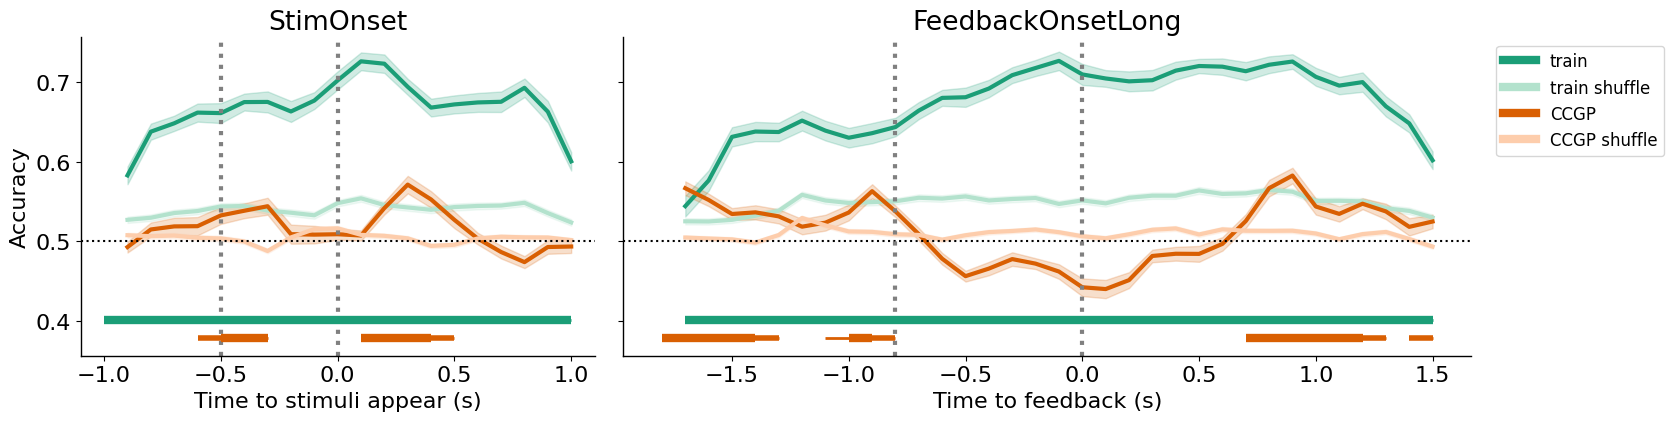

In [4]:
# event markers, as in visualization_utils.plot_combined_accs
EVENT_LINES = {"StimOnset": [-0.5, 0], "FeedbackOnsetLong": [-0.8, 0]}
EVENT_XLABELS = {"StimOnset": "Time to stimuli appear (s)", "FeedbackOnsetLong": "Time to feedback (s)"}

plt.rcParams.update({'font.size': 16})
width_ratios = [res[res.event == event].Time.nunique() for event in EVENTS]
fig, axs = plt.subplots(1, len(EVENTS), figsize=(17, 4.5), sharey=True, width_ratios=width_ratios)
for ax, event in zip(axs, EVENTS):
    sns.lineplot(
        long_res[long_res.event == event], x="Time", y="Accuracy", hue="condition", hue_order=list(COND_TO_COLOR),
        palette=COND_TO_COLOR, linewidth=3, errorbar="se", ax=ax, legend=(ax is axs[-1]),
    )
    ax.axhline(0.5, linestyle="dotted", color="black")
    for x in EVENT_LINES[event]:
        ax.axvline(x, color='grey', linestyle='dotted', linewidth=3)
    ax.set_title(event)
    ax.set_xlabel(EVENT_XLABELS[event])
    ax.set_ylabel("Accuracy")

# significance bars below the lines, one row per measure, in that measure's color
y_min, y_max = axs[0].get_ylim()
interval = (y_max - y_min) / 15
for ax, event in zip(axs, EVENTS):
    event_p_vals = p_vals[p_vals.event == event]
    for i, (measure, display_name) in enumerate(MEASURE_TO_DISPLAY.items()):
        visualization_utils.plot_sig_bars(event_p_vals[event_p_vals.measure == measure], y_min - interval * (i + 0.5), ax, color=COND_TO_COLOR[display_name])
axs[0].set_ylim(bottom=y_min - interval * (len(MEASURE_TO_DISPLAY) + 0.5))

legend = axs[-1].legend(fontsize=12, loc="upper left", bbox_to_anchor=(1.02, 1))
for line in legend.get_lines():
    line.set_linewidth(6)
visualization_utils.format_plot(list(axs))
fig.tight_layout()

In [5]:
# mean accuracy per bin and condition, next to the p values
for event in EVENTS:
    means = long_res[long_res.event == event].groupby(["Time", "condition"]).Accuracy.mean().unstack()[list(COND_TO_COLOR)]
    ps = p_vals[p_vals.event == event].pivot(index="Time", columns="measure", values="p").rename(columns=lambda m: f"p {MEASURE_TO_DISPLAY[m]}")
    print(event)
    display(means.join(ps).round(3))

StimOnset


,train,train shuffle,CCGP,CCGP shuffle,p CCGP,p train
Time,,,,,,
-0.9,0.583,0.527,0.493,0.508,0.921,0.0
-0.8,0.638,0.530,0.515,0.506,0.218,0.0
-0.7,0.648,0.535,0.519,0.507,0.171,0.0
-0.6,0.662,0.538,0.519,0.504,0.110,0.0
-0.5,0.661,0.544,0.533,0.504,0.002,0.0
-0.4,0.675,0.544,0.538,0.500,0.000,0.0
-0.3,0.675,0.539,0.544,0.488,0.000,0.0
-0.2,0.663,0.536,0.509,0.505,0.346,0.0
-0.1,0.677,0.533,0.508,0.515,0.754,0.0


FeedbackOnsetLong


,train,train shuffle,CCGP,CCGP shuffle,p CCGP,p train
Time,,,,,,
-1.7,0.544,0.525,0.567,0.505,0.000,0.089
-1.6,0.576,0.525,0.552,0.503,0.000,0.000
-1.5,0.631,0.527,0.534,0.502,0.000,0.000
-1.4,0.638,0.532,0.536,0.498,0.000,0.000
-1.3,0.637,0.538,0.531,0.508,0.005,0.000
-1.2,0.652,0.558,0.518,0.529,0.884,0.000
-1.1,0.639,0.551,0.523,0.520,0.347,0.000
-1.0,0.630,0.548,0.536,0.512,0.010,0.000
-0.9,0.636,0.549,0.563,0.512,0.000,0.000


In [6]:
# true minus mean shuffle per dimension pair, averaged over bins and folds
gaps = res.groupby(["event", "dim_a", "dim_b", "shuffle_type"])[["train_acc", "ccgp_acc"]].mean().unstack("shuffle_type")
gaps = pd.DataFrame({
    "train gap": gaps[("train_acc", "true")] - gaps[("train_acc", "shuffle")],
    "CCGP gap": gaps[("ccgp_acc", "true")] - gaps[("ccgp_acc", "shuffle")],
})
gaps.round(4)

train gap  CCGP gap
event             dim_a   dim_b                       
FeedbackOnsetLong Color   Pattern     0.1370    0.0201
                          Shape       0.1126   -0.0052
                  Pattern Shape       0.1266   -0.0084
StimOnset         Color   Pattern     0.1652    0.0440
                          Shape       0.1046   -0.0083
                  Pattern Shape       0.1170    0.0024